# Lab: Linear Regression with multiple feature

## Content
1. Summary of Linear Regression
2. Linear Regression with one feature
3. Linear Regression with multiple features

### Summary of Linear Regression

Upfront:
1. Loss Function is Mean Square Error
2. Optimizer is Gradient Descent

**Linear Regression Model:**
$$
f_{w, b}(x^{(i)}) = wx^{(i)} + b
$$

**Cost Function:** 
$$
J(w, b) = \frac{1}{2m} \sum_{i=1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)})^2
$$

**Gradient Descent:**
$$
\begin{aligned}
& \text{repeat until convergence } \{ \\
& w_n = w_n - \alpha \frac{\partial}{\partial w_n} J(w, b) \\
& b = b - \alpha \frac{\partial}{\partial b} J(w, b) \\
& \}
\end{aligned}
$$

If we calculate the derivatives:
$$
\begin{aligned}
& \text{repeat until convergence } \{ \\
& w_n = w_n - \alpha \frac{1}{m}\sum_{i=1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)}) x^{(i)} \\
& b = b - \alpha \frac{1}{m}\sum_{i=1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)}) \\
& \}
\end{aligned}
$$

#### Algorithm

``` python
While not max_steps:
    1.Find J(w, b)
    2.Find new Weight, and Bias using Gradient Descent

    if new J(w, b) and old J(w, b) has no or very less different
        break 

```

In [58]:
import numpy as np

class LinearRegression:
    def __init__(self, n_iter=10000, convergence_limit=1e-7, learning_rate=0.01):
        self.n_iter = n_iter
        self.convergence_limit = convergence_limit
        self.learning_rate = learning_rate

    def _model(self, X):
        y_hat = np.dot(X, self.weights) + self.bias

        return y_hat

    def _cost_function(self):
        f_wb = self._model(self.X)
        
        J_wb = f_wb - self.y
        J_wb = J_wb ** 2
        J_wb = np.sum(J_wb)
        J_wb = J_wb / (2 * self.m)    

        return J_wb

    def _gradient(self):
        dL_dw = np.zeros(self.n)
        dL_db = 0

        for i in range(self.m):
            dL_df = self._model(self.X[i]) - self.y[i]

            dL_dw += dL_df * self.X[i]
            dL_db += dL_df

        dL_dw = dL_dw / self.m
        dL_db = dL_db / self.m

        return dL_dw, dL_db

    def _gradient_descent(self):
        for i in range(self.n_iter):
            dL_dw, dL_db = self._gradient()

            w_temp = self.weights - self.learning_rate * dL_dw
            b_temp = self.bias - self.learning_rate * dL_db

            self.weights = w_temp
            self.bias = b_temp

            self.history.append(self._cost_function())
            
            converged = len(self.history) > 1 and abs(self.history[-1] - self.history[-2]) < self.convergence_limit
            diverged = not np.isfinite(self.history[-1])
            
            if converged or diverged:
                break

        return self
      
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        # Feature Scaling "z-score"
        self.mean = np.mean(X, axis=0)

        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1.0


        self.X = (X - self.mean) / self.std
        self.y = y

        self.m = self.X.shape[0] # Number of Data Rows
        self.n = self.X.shape[1] # Number of Features

        self.weights = np.zeros(self.n)
        self.bias = 0

        self.history = []

        # Finding best parameters
        self._gradient_descent()

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        # Feature Rescaling (for test data)
        X = (X - self.mean) / self.std
        
        y_hat = self._model(X)

        print("mean:", self.mean, "std:", self.std)
        print("Weights:", self.weights)
        print("Bias:", self.bias)
        print("Prediction:", y_hat)

In [85]:
# Test Data
# y = 4.5*x1 - 2.8*x2 + 3.2 + noise (noise std = 4), 100 samples

X = np.array([
    [  2.74,  -0.61],
    [  3.59,   1.97],
    [ -4.06,   4.76],
    [  2.61,   2.86],
    [ -3.72,  -0.50],
    [ -1.29,   4.27],
    [  1.44,   3.23],
    [ -0.57,  -2.73],
    [  0.55,  -4.36],
    [  3.28,   1.32],
    [  2.58,  -1.45],
    [  4.71,   3.93],
    [  2.78,  -3.05],
    [ -0.33,  -4.56],
    [ -3.46,   1.83],
    [  2.45,   4.68],
    [ -1.74,  -1.30],
    [ -0.30,  -3.11],
    [ -3.70,  -0.24],
    [ -2.73,   1.70],
    [ -0.63,   3.33],
    [  2.00,  -1.88],
    [  3.32,   3.05],
    [ -1.13,  -2.12],
    [  1.82,  -3.60],
    [ -3.00,  -4.93],
    [  2.87,   1.65],
    [  2.05,   2.81],
    [ -0.41,   0.69],
    [ -3.60,  -3.85],
    [  1.68,  -0.29],
    [  0.65,   2.65],
    [  1.35,   0.54],
    [  0.59,  -1.96],
    [ -4.69,  -0.63],
    [ -2.85,  -0.91],
    [  3.53,  -2.66],
    [ -4.42,  -2.19],
    [ -2.06,   1.62],
    [  0.57,   2.84],
    [  1.64,  -0.94],
    [  3.14,  -3.33],
    [ -4.77,  -4.10],
    [  2.22,  -0.38],
    [ -3.39,   0.01],
    [ -3.48,   1.96],
    [ -0.54,  -1.19],
    [ -1.98,   1.30],
    [ -1.38,  -4.12],
    [ -3.82,   4.62],
    [  4.09,   2.00],
    [ -2.34,   4.69],
    [  2.79,   2.17],
    [ -0.51,  -2.28],
    [ -4.04,   4.03],
    [ -0.44,  -2.98],
    [ -1.94,   0.79],
    [ -3.23,   3.57],
    [  2.59,   2.19],
    [ -0.68,   1.27],
    [  0.84,   1.50],
    [ -4.16,  -0.84],
    [ -4.58,  -0.06],
    [ -1.70,  -3.55],
    [ -3.97,   0.88],
    [ -3.29,   4.25],
    [  0.81,  -1.53],
    [  0.91,  -4.77],
    [  4.59,  -0.18],
    [  2.83,  -4.17],
    [ -0.13,  -0.09],
    [  4.38,   0.72],
    [ -0.27,  -2.33],
    [ -1.68,   0.21],
    [ -0.61,  -4.78],
    [  3.26,   3.96],
    [ -3.60,   0.54],
    [ -3.91,   1.72],
    [ -2.19,   1.59],
    [  2.27,   2.69],
    [ -3.92,   4.16],
    [ -2.70,  -4.63],
    [  0.55,  -1.29],
    [  3.30,   3.08],
    [ -1.83,   4.53],
    [ -2.09,   0.15],
    [ -2.44,   4.36],
    [ -3.35,  -4.55],
    [ -0.65,   4.92],
    [  3.92,   2.49],
    [  3.91,   3.93],
    [  0.19,  -1.84],
    [  2.72,   1.62],
    [ -1.26,  -4.06],
    [  2.47,  -2.38],
    [  4.37,  -2.59],
    [ -3.77,   3.31],
    [ -3.47,  -3.21],
    [  0.99,   3.75],
    [ -3.04,  -1.90],
])

y = np.array([
      19.81,   12.26,  -28.42,    6.28,  -10.79,
      -8.93,    1.00,   10.85,    9.68,   14.07,
      15.50,    8.52,   20.74,   13.15,  -13.83,
      -4.18,   -0.87,    8.62,  -14.09,   -9.83,
      -6.81,   22.81,    8.98,    1.27,   20.57,
       4.47,   12.20,    0.22,   -0.22,   -1.31,
      21.64,    6.21,    4.35,   10.19,  -21.99,
      -9.44,   27.80,   -5.73,  -13.52,   -4.80,
       4.62,   26.00,  -11.03,   12.14,  -15.59,
     -18.33,   -2.93,  -15.22,   17.04,  -32.08,
      11.62,  -13.11,   21.30,    2.60,  -27.74,
      10.93,   -0.83,  -25.28,    7.74,   -0.31,
       4.52,  -14.67,  -17.78,   -0.01,  -18.08,
     -24.57,   12.06,   18.43,   26.25,   31.66,
       3.49,   22.30,    8.72,   -4.95,   10.95,
       8.05,  -14.90,  -10.84,   -4.81,    7.43,
     -29.14,   -0.44,   14.05,   10.48,  -15.80,
     -13.60,  -16.28,    2.68,  -17.94,   11.98,
      10.85,    9.42,    9.74,    8.48,   19.97,
      30.73,  -17.15,  -13.69,   -3.79,   -4.45,
])

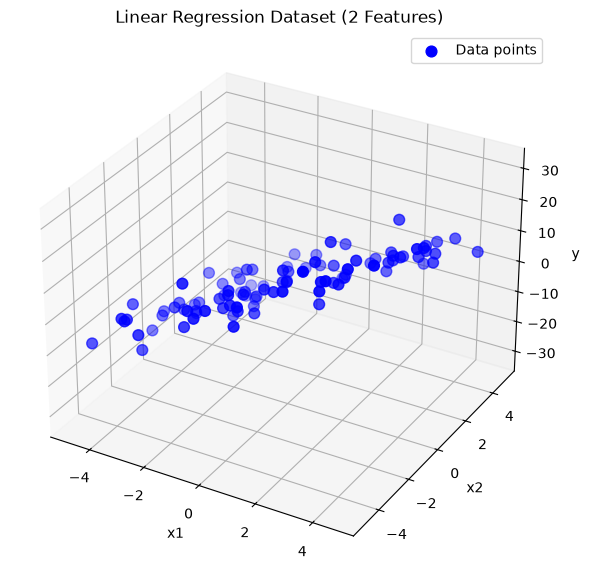

In [86]:
import matplotlib.pyplot as plt

# Extract features
x1 = X[:, 0]
x2 = X[:, 1]

# Create 3D plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

# Plot data points
ax.scatter(x1, x2, y, color="blue", s=60, label="Data points")

# Labels
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
ax.set_title("Linear Regression Dataset (2 Features)")

ax.legend()
plt.show()

In [ ]:
# Four different Linear Regression mode with learning rate change
lr1 = LinearRegression(n_iter=10000, convergence_limit=1e-7, learning_rate=0.01)
lr2 = LinearRegression(n_iter=10000, convergence_limit=1e-7, learning_rate=0.001)
lr3 = LinearRegression(n_iter=10000, convergence_limit=1e-7, learning_rate=0.0001)
lr4 = LinearRegression(n_iter=10000, convergence_limit=1e-7, learning_rate=0)

lr1.fit(X, y)
lr2.fit(X, y)
lr3.fit(X, y)
lr4.fit(X, y)

In [88]:
# Predictions --> 3.8

print("LR1")
lr1.predict([2.0, 3.0])

print("LR2")
lr2.predict([2.0, 3.0])

print("LR3")
lr3.predict([2.0, 3.0])

print("LR4")
lr4.predict([2.0, 3.0])

LR1
mean: [-0.299   0.1769] std: [2.7437294 2.8673457]
Weights: [12.40141217 -7.51510148]
Bias: 1.1730256436710773
Prediction: 4.165163846319295
LR2
mean: [-0.299   0.1769] std: [2.7437294 2.8673457]
Weights: [12.39573878 -7.5106585 ]
Bias: 1.1726056602733947
Prediction: 4.16436449310532
LR3
mean: [-0.299   0.1769] std: [2.7437294 2.8673457]
Weights: [ 7.6980177  -4.52180807]
Bias: 0.7416254203248862
Prediction: 2.739843669937235
LR4
mean: [-0.299   0.1769] std: [2.7437294 2.8673457]
Weights: [0. 0.]
Bias: 0.0
Prediction: 0.0


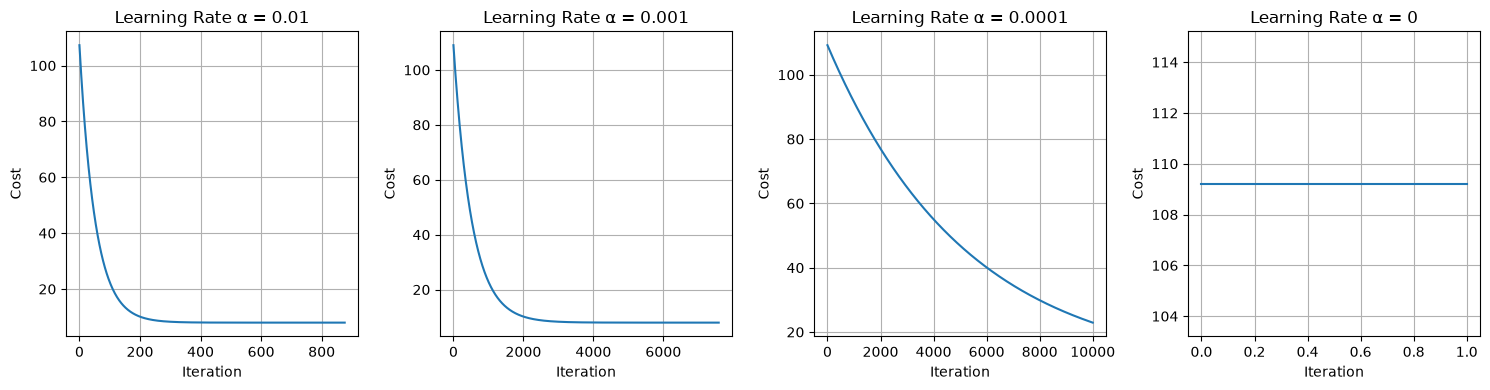

In [89]:
# Cost Function - Loss every iteration
import matplotlib.pyplot as plt

histories = [lr1.history, lr2.history, lr3.history, lr4.history]
alphas = [0.01, 0.001, 0.0001, 0]

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for i, (history, alpha) in enumerate(zip(histories, alphas)):
    axes[i].plot(history)
    axes[i].set_title(f"Learning Rate α = {alpha}")
    axes[i].set_xlabel("Iteration")
    axes[i].set_ylabel("Cost")
    axes[i].grid(True)

plt.tight_layout()
plt.show()